# Когортный анализ, RFM-сегментация и LTV клиентов интернет-магазина

**Контекст.** Интернет-магазин растёт по выручке, но маркетинг тратит всё больше на привлечение.
Руководитель хочет понять:

1. Как ведут себя клиенты после первой покупки — возвращаются ли они (**когортный анализ**)?
2. На какие группы делится база и что делать с каждой (**RFM-сегментация** для CRM-рассылок)?
3. Какие каналы привлечения приводят *ценных* клиентов, а какие — разовых (**LTV по каналам**)?

**Данные:** SQLite-база `data/shop.db` — таблицы `customers` и `orders`, январь 2025 – июнь 2026.
Все расчёты сделаны SQL-запросами из папки `sql/` (CTE, оконные функции `LAG`, `NTILE`),
Python используется для визуализации.

> Данные синтетические (генератор — `src/generate_data.py`), параметры близки к типичным для e-commerce.

In [1]:
import sqlite3
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 4)
con = sqlite3.connect("data/shop.db")

def q(name):
    return pd.read_sql(Path(f"sql/{name}.sql").read_text(), con)

In [2]:
pd.read_sql('''
SELECT (SELECT COUNT(*) FROM customers)                           AS customers,
       (SELECT COUNT(*) FROM orders)                              AS orders,
       (SELECT ROUND(100.0*AVG(status='cancelled'),1) FROM orders) AS cancelled_pct,
       (SELECT MIN(order_date) FROM orders)                       AS first_order,
       (SELECT MAX(order_date) FROM orders)                       AS last_order
''', con)

,customers,orders,cancelled_pct,first_order,last_order
0,20696,31537,5.9,2025-01-01,2026-06-30


## 1. Динамика бизнеса по месяцам  (`sql/01_monthly_metrics.sql`)

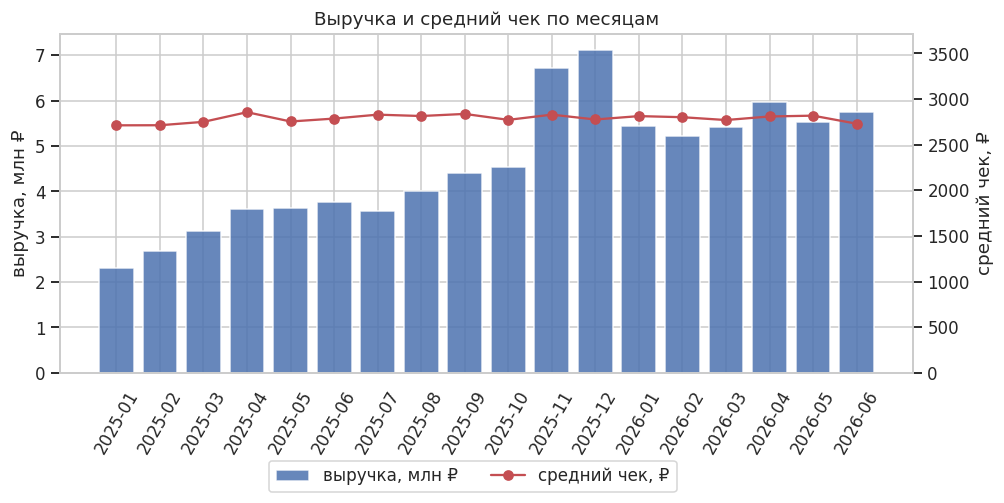

,month,orders,buyers,revenue,avg_check,revenue_mom_pct
12,2026-01,1936,1936,5445660.0,2813.0,-23.4
13,2026-02,1865,1865,5223527.0,2801.0,-4.1
14,2026-03,1957,1957,5420539.0,2770.0,3.8
15,2026-04,2123,2123,5963766.0,2809.0,10.0
16,2026-05,1959,1959,5520087.0,2818.0,-7.4
17,2026-06,2103,2103,5740163.0,2730.0,4.0


In [3]:
monthly = q("01_monthly_metrics")
fig, ax1 = plt.subplots()
ax1.bar(monthly.month, monthly.revenue / 1e6, color="#4C72B0", alpha=.85, label="выручка, млн ₽")
ax1.set_ylabel("выручка, млн ₽"); ax1.tick_params(axis="x", rotation=60)
ax2 = ax1.twinx(); ax2.grid(False)
ax2.plot(monthly.month, monthly.avg_check, color="#C44E52", marker="o", label="средний чек, ₽")
ax2.set_ylabel("средний чек, ₽"); ax2.set_ylim(0, monthly.avg_check.max() * 1.3)
ax1.set_title("Выручка и средний чек по месяцам")
fig.legend(loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.18));
monthly.tail(6)

Выручка за полтора года выросла в 2,5 раза, пик — ноябрь-декабрь (сезон распродаж), средний чек стабилен ≈ 2 800 ₽.
Значит рост идёт за счёт **числа покупателей**. Вопрос — это новые клиенты или вернувшиеся?

## 2. Когортный анализ удержания  (`sql/02_cohort_retention.sql`)

Когорта — клиенты, сделавшие первую покупку в одном месяце. Retention месяца N — доля когорты,
купившая снова через N месяцев.

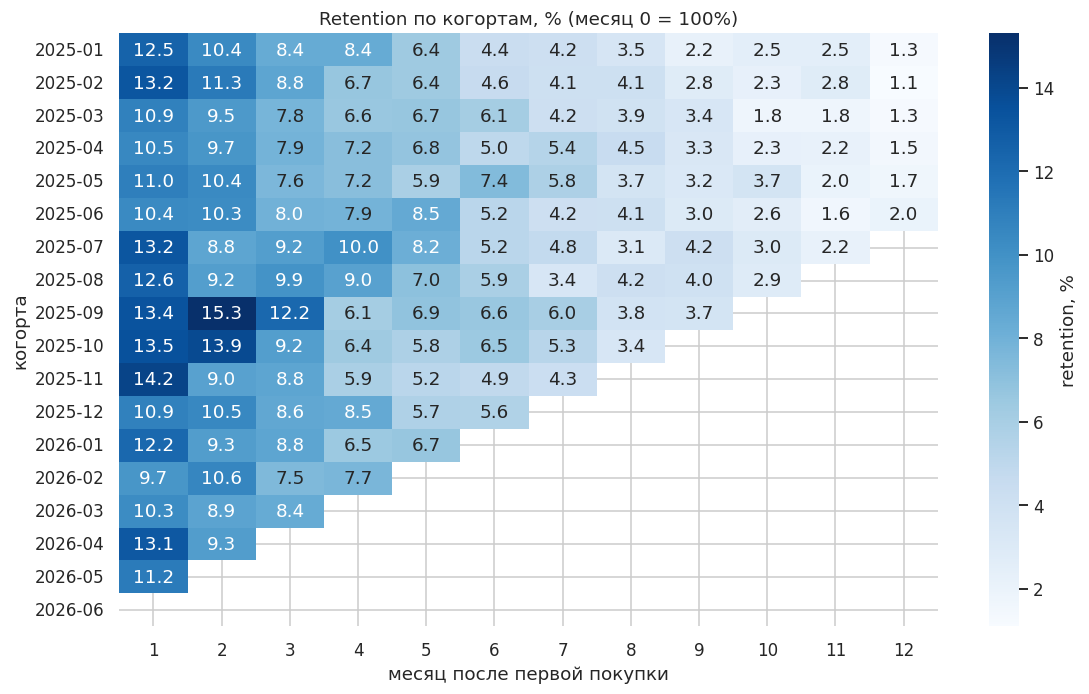

In [4]:
coh = q("02_cohort_retention")
pivot = coh.pivot(index="cohort", columns="month_n", values="retention_pct")
fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(pivot.iloc[:, 1:13], annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "retention, %"}, ax=ax)
ax.set(title="Retention по когортам, % (месяц 0 = 100%)", xlabel="месяц после первой покупки", ylabel="когорта");

In [5]:
avg_ret = pivot.iloc[:, 1:13].mean().round(1)
print("Средний retention по всем когортам, %:")
print(avg_ret.to_string())

Средний retention по всем когортам, %:
month_n
1     11.9
2     10.4
3      8.7
4      7.4
5      6.6
6      5.6
7      4.7
8      3.8
9      3.3
10     2.6
11     2.2
12     1.5


Через месяц возвращаются только **~12% клиентов**, к шестому месяцу — ~5–6%.
Почти 9 из 10 покупателей — разовые. Рост бизнеса держится на привлечении новых,
а это дорого. Разберёмся, где лояльность выше.

## 3. Удержание по каналам привлечения

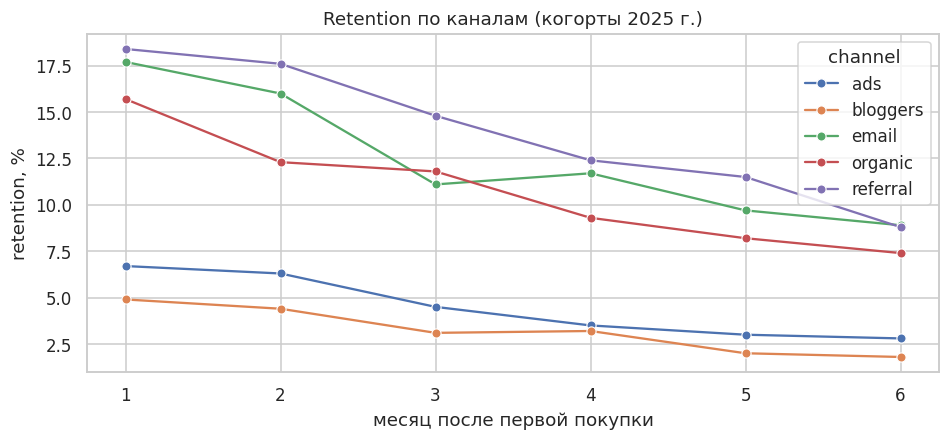

In [6]:
ch_ret = pd.read_sql('''
WITH fp AS (
    SELECT o.customer_id, c.channel, MIN(o.order_date) AS first_date
    FROM orders o JOIN customers c USING (customer_id)
    WHERE o.status = 'delivered'
    GROUP BY o.customer_id
),
act AS (
    SELECT DISTINCT fp.channel, fp.customer_id,
        (CAST(strftime('%Y', o.order_date) AS INT) - CAST(strftime('%Y', fp.first_date) AS INT)) * 12
      + (CAST(strftime('%m', o.order_date) AS INT) - CAST(strftime('%m', fp.first_date) AS INT)) AS month_n
    FROM fp JOIN orders o USING (customer_id)
    WHERE o.status = 'delivered' AND fp.first_date < '2026-01-01'
)
SELECT channel, month_n,
       ROUND(100.0 * COUNT(DISTINCT customer_id) /
             SUM(COUNT(DISTINCT customer_id)) FILTER (WHERE month_n = 0) OVER (PARTITION BY channel), 1) AS retention_pct
FROM act
WHERE month_n BETWEEN 0 AND 6
GROUP BY channel, month_n
''', con)
ax = sns.lineplot(data=ch_ret[ch_ret.month_n > 0], x="month_n", y="retention_pct", hue="channel", marker="o")
ax.set(title="Retention по каналам (когорты 2025 г.)", xlabel="месяц после первой покупки", ylabel="retention, %");

## 4. LTV и окупаемость каналов  (`sql/04_channel_ltv.sql`)

LTV за 6 месяцев — выручка с клиента за первые полгода. Чтобы сравнить с затратами, берём
**допущения** о стоимости привлечения (CAC) от маркетинга и маржинальность 30%.

In [7]:
ltv = q("04_channel_ltv")
CAC = {"organic": 450, "ads": 1400, "referral": 700, "email": 250, "bloggers": 1600}   # допущение, ₽
MARGIN = 0.30
ltv["CAC"] = ltv.channel.map(CAC)
ltv["gross_profit_6m"] = (ltv.ltv_6m * MARGIN).round()
ltv["ROMI_6m_pct"] = ((ltv.gross_profit_6m - ltv.CAC) / ltv.CAC * 100).round(0)
ltv

,channel,customers,repeat_rate_pct,orders_per_customer,ltv_6m,CAC,gross_profit_6m,ROMI_6m_pct
0,referral,1974,51.2,1.79,5481.0,700,1644.0,135.0
1,email,1286,47.9,1.70,4729.0,250,1419.0,468.0
2,organic,3867,43.4,1.61,4697.0,450,1409.0,213.0
3,ads,4348,21.6,1.25,3281.0,1400,984.0,-30.0
4,bloggers,1272,17.0,1.18,2709.0,1600,813.0,-49.0


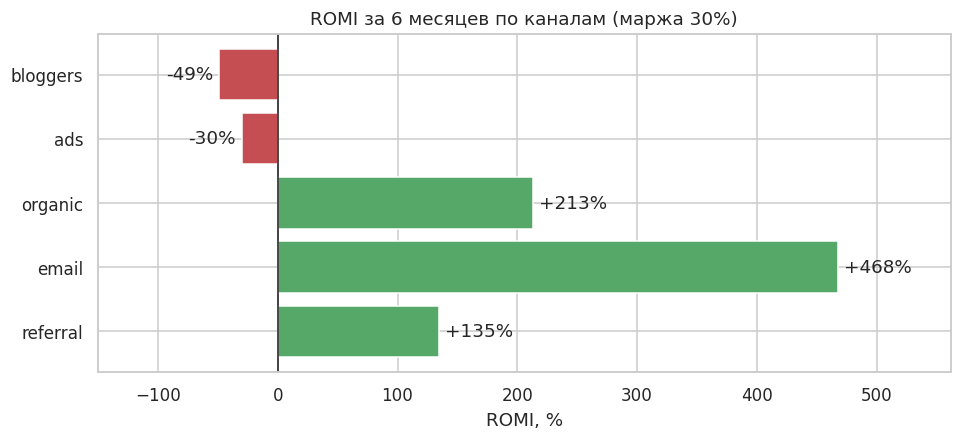

In [8]:
fig, ax = plt.subplots()
colors = ["#55A868" if v > 0 else "#C44E52" for v in ltv.ROMI_6m_pct]
ax.barh(ltv.channel, ltv.ROMI_6m_pct, color=colors)
ax.axvline(0, color="k", lw=1)
ax.set_xlim(-150, ltv.ROMI_6m_pct.max() * 1.2)
for i, v in enumerate(ltv.ROMI_6m_pct):
    ax.text(v + (5 if v >= 0 else -5), i, f"{v:+.0f}%", va="center", ha="left" if v >= 0 else "right")
ax.set(title="ROMI за 6 месяцев по каналам (маржа 30%)", xlabel="ROMI, %");

## 5. RFM-сегментация  (`sql/03_rfm.sql`)

In [9]:
rfm = q("03_rfm")
seg = (rfm.groupby("segment")
          .agg(customers=("customer_id", "count"), recency_days=("recency", "median"),
               orders=("frequency", "mean"), revenue=("monetary", "sum"))
          .assign(share_customers=lambda d: (d.customers / d.customers.sum() * 100).round(1),
                  share_revenue=lambda d: (d.revenue / d.revenue.sum() * 100).round(1))
          .sort_values("revenue", ascending=False))
seg["orders"] = seg["orders"].round(1)
seg

,customers,recency_days,orders,revenue,share_customers,share_revenue
segment,,,,,,
Лояльные,4614,118.0,2.4,31428007.0,23.3,37.9
Потерянные,5051,403.0,1.0,13690964.0,25.5,16.5
Засыпающие,4246,192.0,1.0,11490991.0,21.4,13.9
Новички,3939,53.0,1.0,10694192.0,19.9,12.9
Под угрозой ухода,1551,347.0,2.3,9794805.0,7.8,11.8
Чемпионы,405,46.0,4.8,5742554.0,2.0,6.9


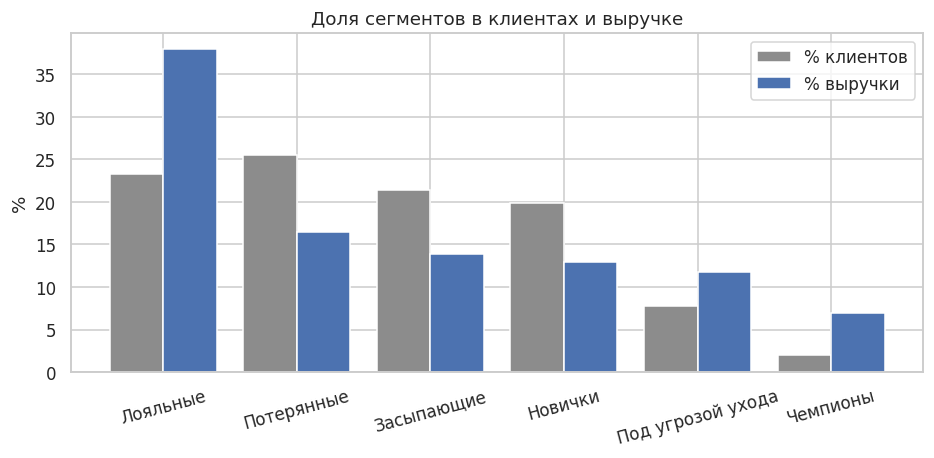

In [10]:
fig, ax = plt.subplots()
x = np.arange(len(seg))
ax.bar(x - 0.2, seg.share_customers, 0.4, label="% клиентов", color="#8C8C8C")
ax.bar(x + 0.2, seg.share_revenue, 0.4, label="% выручки", color="#4C72B0")
ax.set_xticks(x, seg.index, rotation=15); ax.legend()
ax.set(title="Доля сегментов в клиентах и выручке", ylabel="%");

In [11]:
# выгрузки для дашборда в Power BI
Path("exports").mkdir(exist_ok=True)
monthly.to_csv("exports/monthly_metrics.csv", index=False)
coh.to_csv("exports/cohort_retention.csv", index=False)
rfm.to_csv("exports/rfm_segments.csv", index=False)
ltv.to_csv("exports/channel_ltv.csv", index=False)
print("CSV для Power BI сохранены в exports/")

CSV для Power BI сохранены в exports/


## 6. Выводы и рекомендации

**Что происходит**
- Выручка растёт за счёт новых клиентов: средний чек не меняется, а через месяц возвращаются лишь ~12%.
- Каналы сильно различаются по качеству: клиенты из **рефералов, email и органики** возвращаются
  в 2–3 раза чаще, чем из **рекламы и блогеров**, и приносят в 1,5–2 раза больше за полгода.
- С учётом стоимости привлечения **блогеры и платная реклама не окупаются за 6 месяцев**,
  реферальная программа и email окупаются многократно.
- «Лояльные» и «Чемпионы» — четверть клиентов, но почти половина выручки (45%).
  «Под угрозой ухода» — клиенты, покупавшие не раз, но пропавшие почти на год.

**Что сделать**

| Сегмент / канал | Действие | Метрика успеха |
|---|---|---|
| Чемпионы | программа лояльности, ранний доступ к распродажам | доля повторных заказов |
| Лояльные | персональные подборки, кросс-селл | частота покупок |
| Новички | welcome-цепочка писем, промокод на 2-й заказ в течение 30 дней | retention 1-го месяца |
| Под угрозой ухода | реактивационная рассылка с персональной скидкой | доля вернувшихся |
| Реклама, блогеры | пересмотреть бюджеты, оценивать кампании по LTV, а не по числу заказов | ROMI 6 мес. |
| Рефералы | масштабировать программу «приведи друга» | число новых клиентов из канала |

Эффект каждой механики стоит проверять A/B-тестом (например, промокод на 2-й заказ vs контроль).